# Tugas 1 : pemilihan fitur dan k pada data kafe

In [1]:
# Langkah 1 - Load Data
import pandas as pd
data = pd.read_csv('../../dataset_pbl/cafes.csv')
data['source_query'] = data['source_query'].fillna('Tidak tersedia')
data = data[['latitude', 'longitude', 'rating', 'review_count', 'source_query']]
import numpy as np
import matplotlib.pyplot as plt
data.head()

,latitude,longitude,rating,review_count,source_query
0,-7.970043,112.631764,4.7,167,Tidak tersedia
1,-7.979534,112.630695,4.5,1575,Tidak tersedia
2,-7.963036,112.625030,4.9,316,Tidak tersedia
3,-7.972555,112.618455,4.6,1772,Tidak tersedia
4,-7.961104,112.651613,4.6,596,Tidak tersedia


In [2]:
# Langkah 2 - Pisahkan fitur, target, dan data uji
from sklearn.model_selection import train_test_split
features = ['latitude', 'longitude', 'rating', 'review_count']
X = data[features]
y = data['source_query']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [3]:
# Langkah 3 - Percobaan jumlah fitur dan k secara langsung
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
hasil = []
for jumlah in range(1, len(features) + 1):
    kolom = features[:jumlah]
    scaler = StandardScaler()
    train = scaler.fit_transform(X_train[kolom])
    test = scaler.transform(X_test[kolom])
    for k in range(1, 11):
        model = KNeighborsClassifier(n_neighbors=k).fit(train, y_train)
        hasil.append({'Jumlah fitur': jumlah, 'K': k, 'Akurasi uji': model.score(test, y_test)})
tabel = pd.DataFrame(hasil)
tabel

,Jumlah fitur,K,Akurasi uji
0,1,1,0.318681
1,1,2,0.329670
2,1,3,0.351648
3,1,4,0.439560
4,1,5,0.450549
5,1,6,0.450549
6,1,7,0.461538
7,1,8,0.461538
8,1,9,0.461538
9,1,10,0.483516


In [4]:
# Langkah 4 - Pilih konfigurasi dari hasil percobaan
terbaik = max(hasil, key=lambda row: row['Akurasi uji'])
kolom = features[:terbaik['Jumlah fitur']]
scaler = StandardScaler()
train = scaler.fit_transform(X_train[kolom])
test = scaler.transform(X_test[kolom])
model = KNeighborsClassifier(n_neighbors=terbaik['K']).fit(train, y_train)
print('Konfigurasi:', terbaik)
print('Fitur:', kolom)

Konfigurasi: {'Jumlah fitur': 2, 'K': 8, 'Akurasi uji': 0.8021978021978022}
Fitur: ['latitude', 'longitude']


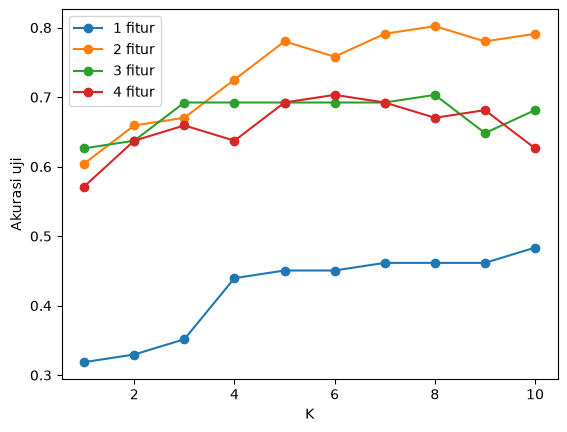

In [5]:
# Langkah 5 - Grafik k dan jumlah fitur
for jumlah, group in tabel.groupby('Jumlah fitur'):
    plt.plot(group['K'], group['Akurasi uji'], marker='o', label=f'{jumlah} fitur')
plt.xlabel('K')
plt.ylabel('Akurasi uji')
plt.legend()
plt.show()

In [6]:
# Langkah 6 - Evaluasi konfigurasi terpilih
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
y_pred = model.predict(test)
print('Akurasi:', accuracy_score(y_test, y_pred))
print('Confusion matrix:', confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Akurasi: 0.8021978021978022
Confusion matrix: [[ 9  0  0  0  0  0  0]
 [ 0  6  0  0  0  2  1]
 [ 0  0  6  0  0  0  3]
 [ 0  0  0  9  0  0  0]
 [ 0  0  0  0  8  0  0]
 [ 0  0  0  0  0  9  0]
 [ 5  0  3  1  0  3 26]]
                            precision    recall  f1-score   support

      Cafe Blimbing Malang       0.64      1.00      0.78         9
        Cafe Dinoyo Malang       1.00      0.67      0.80         9
          Cafe Ijen Malang       0.67      0.67      0.67         9
     Cafe Sawojajar Malang       0.90      1.00      0.95         9
  Cafe Sigura gura  Malang       1.00      1.00      1.00         8
Cafe Soekarno Hatta Malang       0.64      1.00      0.78         9
            Tidak tersedia       0.87      0.68      0.76        38

                  accuracy                           0.80        91
                 macro avg       0.82      0.86      0.82        91
              weighted avg       0.83      0.80      0.80        91



## Hasil

Konfigurasi dengan akurasi uji tertinggi pada percobaan: k=8, fitur latitude, longitude, akurasi 80.22%.